                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
Dataset Shape: (50000, 2)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 142s 270ms/step - accuracy: 0.5993 - loss: 0.6433 - val_accuracy: 0.7335 - val_loss: 0.5375
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 130s 246ms/step - accuracy: 0.7619 - loss: 0.5125 - val_accuracy: 0.6110 - val_loss: 0.6033
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 142s 246ms/step - accuracy: 0.8173 - loss: 0.4262 - val_accuracy: 0.8450 - val_loss: 0.4051
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 149s 260ms/step - accuracy: 0.6899 - loss: 0.5266 - val_accuracy: 0.6560 - val_loss: 0.5747
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 133s 242ms/step - accuracy: 0.7799 - loss: 0.4412 - val_accuracy: 0.8550 - val_loss: 0.3918
313/313 ━━━━━━━━━━━━━━━━━━━━ 22s 66ms/step - accuracy: 0.8530 - loss: 0.3878

Test Loss: 0.3877581059932709
Test Accuracy: 85.3 %


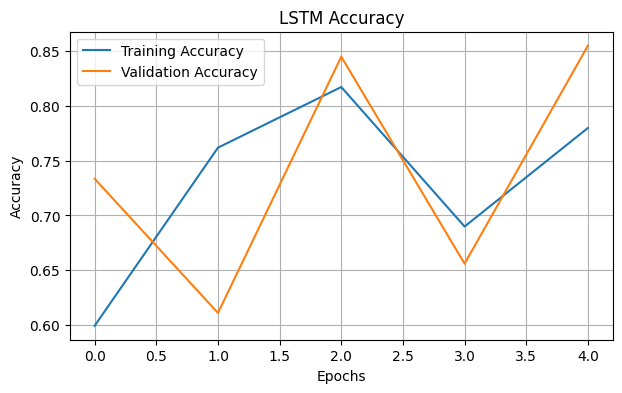

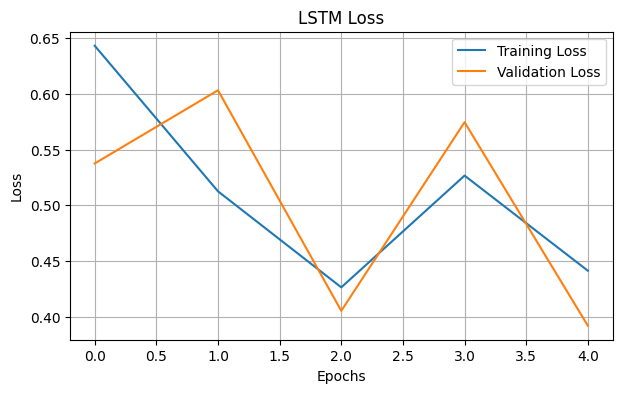

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step

ACTUAL VS PREDICTED SENTIMENT

Review 1
Actual   : Negative
Predicted: Negative
Probability: 0.8990287

Review 2
Actual   : Negative
Predicted: Positive
Probability: 0.8688245

Review 3
Actual   : Positive
Predicted: Positive
Probability: 0.8926318

Review 4
Actual   : Negative
Predicted: Negative
Probability: 0.9214757

Review 5
Actual   : Negative
Predicted: Negative
Probability: 0.9118595
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 344ms/step

CUSTOM REVIEW PREDICTIONS

Review: This movie was amazing and I really enjoyed it
Predicted: Positive
Probability: 0.8732671

Review: The movie was boring and disappointing
Predicted: Positive
Probability: 0.8663968

Review: Excellent acting and wonderful storyline
Predicted: Positive
Probability: 0.8733459

Review: Worst movie ever, I wasted my time
Predicted: Negative
Probability: 0.5266961


In [3]:
# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from sklearn.model_selection import train_test_split

# Step 2: Load CSV Dataset
data = pd.read_csv("IMDB_Dataset.csv")

print(data.head())
print("Dataset Shape:", data.shape)

# Step 3: Prepare Data
data['sentiment'] = data['sentiment'].map({
    'positive': 1, 'negative': 0
})

X = data['review'].astype(str).values
y = data['sentiment'].values

# Step 4: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 5: Tokenization
vocab_size = 10000
max_length = 200

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train = tokenizer.texts_to_sequences(X_train)
X_test = tokenizer.texts_to_sequences(X_test)

X_train = pad_sequences(X_train, maxlen=max_length, padding='post')
X_test = pad_sequences(X_test, maxlen=max_length, padding='post')

# Step 6: Build LSTM Model
model = Sequential([
    Embedding(vocab_size, 64),
    LSTM(64),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

# Step 7: Train Model
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

# Step 8: Evaluate Model
loss, accuracy = model.evaluate(X_test, y_test)

print("\nTest Loss:", loss)
print("Test Accuracy:", round(accuracy * 100, 2), "%")

# Step 9: Accuracy Graph
plt.figure(figsize=(7, 4))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('LSTM Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

# Step 10: Loss Graph
plt.figure(figsize=(7, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('LSTM Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

# Step 11: Actual vs Predicted Sentiment
predictions = model.predict(X_test[:5])

print("\nACTUAL VS PREDICTED SENTIMENT")

for i in range(5):
    actual = "Positive" if y_test[i] == 1 else "Negative"
    predicted = "Positive" if predictions[i][0] >= 0.5 else "Negative"

    confidence = predictions[i][0] if predictions[i][0] >= 0.5 else 1-predictions[i][0]

    print(f"\nReview {i+1}")
    print("Actual   :", actual)
    print("Predicted:", predicted)
    print("Probability:", round(float(confidence), 7))

# Step 12: Custom Review Predictions
reviews = [
    "This movie was amazing and I really enjoyed it",
    "The movie was boring and disappointing",
    "Excellent acting and wonderful storyline",
    "Worst movie ever, I wasted my time"
]

seq = tokenizer.texts_to_sequences(reviews)
pad = pad_sequences(seq, maxlen=max_length, padding='post')
pred = model.predict(pad)

print("\nCUSTOM REVIEW PREDICTIONS")

for review, p in zip(reviews, pred):
    sentiment = "Positive" if p[0] >= 0.5 else "Negative"
    confidence = p[0] if p[0] >= 0.5 else 1-p[0]

    print("\nReview:", review)
    print("Predicted:", sentiment)
    print("Probability:", round(float(confidence), 7))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 145s 8us/step
Training Samples: 25000
Testing Samples: 25000
Training Data Shape: (25000, 200)
Testing Data Shape: (25000, 200)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_2 (LSTM)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 46s 133ms/step - accuracy: 0.5145 - loss: 0.6931 - val_accuracy: 0.5508 - val_loss: 0.6824
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 133ms/step - accuracy: 0.5832 - loss: 0.6597 - val_accuracy: 0.5958 - val_loss: 0.6464
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 79s 124ms/step - accuracy: 0.6898 - loss: 0.5732 - val_accuracy: 0.5966 - val_loss: 0.6525
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 43s 137ms/step - accuracy: 0.8091 - loss: 0.4671 - val_accuracy: 0.7792 - val_loss: 0.5195
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 46s 147ms/step - accuracy: 0.8025 - loss: 0.4561 - val_accuracy: 0.5284 - val_loss: 0.6874
782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 40ms/step - accuracy: 0.5316 - loss: 0.6879

Test Loss: 0.6878572106361389
Test Accuracy: 53.16399931907654 %


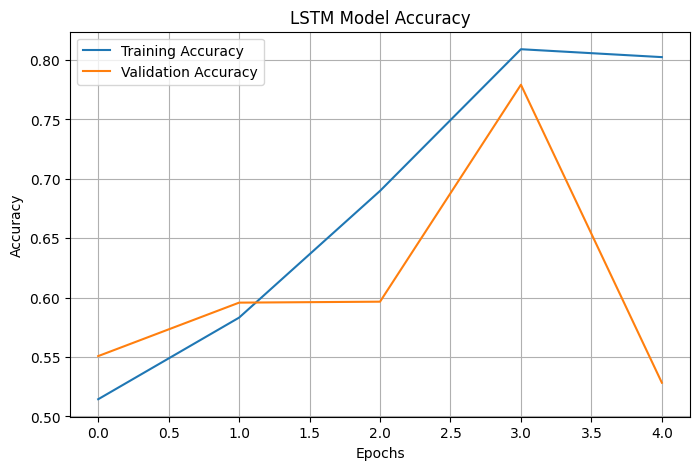

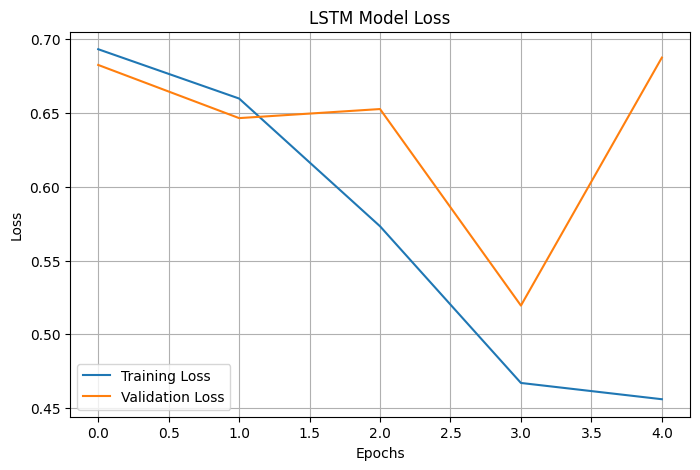

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 317ms/step

ACTUAL VS PREDICTED SENTIMENT

Review: 1
Actual Sentiment   : Negative
Predicted Sentiment: Positive
Probability        : 0.5517
----------------------------------------
Review: 2
Actual Sentiment   : Positive
Predicted Sentiment: Positive
Probability        : 0.5564
----------------------------------------
Review: 3
Actual Sentiment   : Positive
Predicted Sentiment: Negative
Probability        : 0.5796
----------------------------------------
Review: 4
Actual Sentiment   : Negative
Predicted Sentiment: Positive
Probability        : 0.5516
----------------------------------------
Review: 5
Actual Sentiment   : Positive
Predicted Sentiment: Positive
Probability        : 0.5517
----------------------------------------
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 3s 2us/step

Review: This movie was amazing and I really enjoyed it
Predicted Sentiment: Positive
Probability: 0.5517

Review: The movie was boring and disappointing
Predicted Sentiment: Positive
P

In [4]:
# Practical 6: Implement an LSTM for Text Classification
# Dataset: IMDB (TensorFlow Built-in Dataset)

# 1. Import Libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# 2. Load IMDB Dataset using TensorFlow
vocab_size = 10000
max_length = 200

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.imdb.load_data(
    num_words=vocab_size
)

print("Training Samples:", len(x_train))
print("Testing Samples:", len(x_test))

# 3. Pad Sequences
x_train = pad_sequences(
    x_train, maxlen=max_length, padding='post', truncating='post'
)

x_test = pad_sequences(
    x_test, maxlen=max_length, padding='post', truncating='post'
)

print("Training Data Shape:", x_train.shape)
print("Testing Data Shape:", x_test.shape)

# 4. Build LSTM Model
model = Sequential([
    Embedding(vocab_size, 64),
    LSTM(64),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

# 5. Compile Model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# 6. Train Model
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

# 7. Evaluate Model
loss, accuracy = model.evaluate(x_test, y_test)

print("\nTest Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

# 8. Plot Accuracy Graph
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('LSTM Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

# 9. Plot Loss Graph
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('LSTM Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

# 10. Predict Sentiment on Test Data
predictions = model.predict(x_test[:5])

print("\nACTUAL VS PREDICTED SENTIMENT\n")

for i in range(5):

    actual = "Positive" if y_test[i] == 1 else "Negative"

    predicted = "Positive" if predictions[i][0] >= 0.5 else "Negative"

    confidence = (
        predictions[i][0]
        if predictions[i][0] >= 0.5
        else 1 - predictions[i][0]
    )

    print("Review:", i + 1)
    print("Actual Sentiment   :", actual)
    print("Predicted Sentiment:", predicted)
    print("Probability        :", round(float(confidence), 4))
    print("-" * 40)

# 11. Predict Custom Reviews
word_index = tf.keras.datasets.imdb.get_word_index()

def preprocess_review(review):

    words = review.lower().split()

    sequence = [1]  # Start token

    for word in words:
        index = word_index.get(word, 2) + 3

        if index >= vocab_size:
            index = 2

        sequence.append(index)

    sequence = pad_sequences(
        [sequence],
        maxlen=max_length,
        padding='post',
        truncating='post'
    )

    return sequence

def predict_review(review):

    processed = preprocess_review(review)

    prediction = model.predict(processed, verbose=0)[0][0]

    sentiment = "Positive" if prediction >= 0.5 else "Negative"

    confidence = prediction if prediction >= 0.5 else 1 - prediction

    print("\nReview:", review)
    print("Predicted Sentiment:", sentiment)
    print("Probability:", round(float(confidence), 4))

# Test Custom Reviews
predict_review("This movie was amazing and I really enjoyed it")

predict_review("The movie was boring and disappointing")

predict_review("Excellent acting and wonderful storyline")

predict_review("Worst movie ever, I wasted my time")

Dataset Shape: (50000, 2)
Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 53s 90ms/step - accuracy: 0.6403 - loss: 0.6259 - val_accuracy: 0.8257 - val_loss: 0.4800
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 90ms/step - accuracy: 0.6739 - loss: 0.6044 - val_accuracy: 0.6535 - val_loss: 0.6084
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 80s 85ms/step - accuracy: 0.6568 - loss: 0.5517 - val_accuracy: 0.6494 - val_loss: 0.5549
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 83s 88ms/step - accuracy: 0.7137 - loss: 0.5159 - val_accuracy: 0.8399 - val_loss: 0.4290
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 36s 73ms/step - accuracy: 0.7930 - loss: 0.4952 - val_accuracy: 0.5060 - val_loss: 0.9516
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 28ms/step - accuracy: 0.5105 - loss: 0.9469
Test Accuracy: 51.05 %


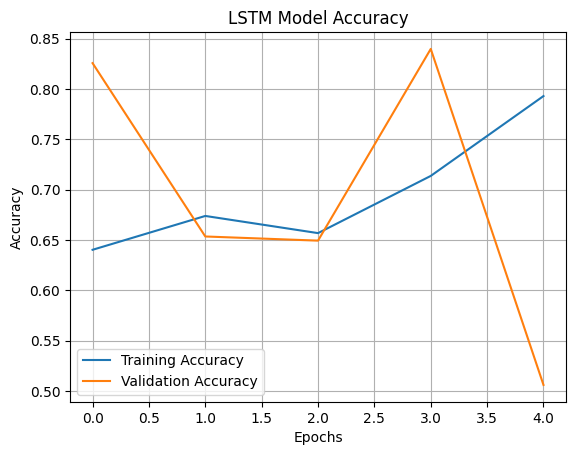

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 394ms/step

Actual vs Predicted Sentiment

Review: 1
Actual Sentiment: Positive
Predicted Sentiment: Positive

Review: 2
Actual Sentiment: Positive
Predicted Sentiment: Positive

Review: 3
Actual Sentiment: Negative
Predicted Sentiment: Positive

Review: 4
Actual Sentiment: Positive
Predicted Sentiment: Positive

Review: 5
Actual Sentiment: Negative
Predicted Sentiment: Positive


In [5]:
# LSTM 

# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from sklearn.model_selection import train_test_split

# Step 2: Load IMDB Dataset
data = pd.read_csv("IMDB_Dataset.csv")

print("Dataset Shape:", data.shape)

# Step 3: Prepare Data
X = data['review'].astype(str)
y = data['sentiment'].map({'positive': 1, 'negative': 0})

# Step 4: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 5: Tokenization and Padding
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train = tokenizer.texts_to_sequences(X_train)
X_test = tokenizer.texts_to_sequences(X_test)

X_train = pad_sequences(X_train, maxlen=200, padding='post')
X_test = pad_sequences(X_test, maxlen=200, padding='post')

# Step 6: Build LSTM Model
model = Sequential([
    Embedding(10000, 32),
    LSTM(32),
    Dense(1, activation='sigmoid')
])

# Step 7: Compile Model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Step 8: Train Model
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

# Step 9: Evaluate Model
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", round(accuracy * 100, 2), "%")

# Step 10: Plot Accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("LSTM Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# Step 11: Example Predictions
predictions = model.predict(X_test[:5])

print("\nActual vs Predicted Sentiment")

for i in range(5):
    actual = "Positive" if y_test.iloc[i] == 1 else "Negative"
    predicted = "Positive" if predictions[i][0] >= 0.5 else "Negative"

    print("\nReview:", i + 1)
    print("Actual Sentiment:", actual)
    print("Predicted Sentiment:", predicted)  